# Разработка рекомендательной системы фильмов


Разработать рекомаендательную систему фильмов по датасетам пользователей, их оценок, фильмов, разработать API, приложение, описать проделанную работу в отчете.

Содержание:
1. Датасеты пользователей, их оценок и фильмов был найден на сайте Kaggle на китайском языке, данные были переведы и сохранены в нужные файлы на русском.
2. Разведочный анализ
3. Рекомендации на основе популярности
4. Коллаборатиная фильтрация
5. Рекомендации по содержанию
6. Гибридный подход
7. Оценка качества
8. Выводы

## 1. Разведочный анализ русскоязычных датасетов

In [37]:
import os, re, sys, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
movies = pd.read_csv("data/movies_ru.csv", low_memory=False, on_bad_lines="skip")
ratings = pd.read_csv("data/ratings_ru.csv")
users   = pd.read_csv("data/users_ru.csv")
print("фильмы:", movies.shape, "| оценки:", ratings.shape, "| пользователи:", users.shape)
movies.head()

фильмы: (34011, 16) | оценки: (1175057, 5) | пользователи: (2712, 7)


,movie_id,title_ru,title_orig,title_translated,year,genres_ru,tags_ru,country_ru,language_ru,director_ru,avg_rating,n_ratings,rating_source,n_raters_source,douban_id,imdb
0,1,Разборка в Токио,功夫,True,2004.0,"Комедия, Боевик","Стивен Чоу, Гонконг, гонконгское кино, кино",Китай,Китайский (кантонский),Стивен Чоу,4.205,410,7.2,62585,1291543,http://www.imdb.com/title/tt0373074/
1,2,Harry Potter and the Prisoner of Azkaban,Harry Potter and the Prisoner of Azkaban,True,2004.0,Фэнтези,"США, американское кино, Великобритания, кино",Великобритания,Английский,Alfonso Cuarón,4.160,262,7.6,34633,1291544,http://www.imdb.com/title/tt0304141/
2,3,Big Fish,Big Fish,True,2003.0,"Фэнтези, Семейный","США, американское кино, сказка, кино",США,Английский,Tim Burton,4.316,487,8.7,51453,1291545,http://www.imdb.com/title/tt0319061/
3,5,Dead Poets Society,Dead Poets Society,True,1989.0,Молодёжный,"США, взросление, вдохновляющее, американское к...",США,Английский,Peter Weir,4.354,506,8.8,45793,1291548,http://www.imdb.com/title/tt0097165/
4,6,Les choristes,Les choristes,True,2004.0,Музыка,"Франция, французское кино, взросление, классик...",Франция,Французский,Christophe Barratier,4.428,460,9.0,80758,1291549,http://www.imdb.com/title/tt0372824/


**Что в колонках `movies_ru.csv`:**
`movie_id` (номер),
`title_ru` (название по-русски), 
`title_orig` (оригинальное), 
`title_translated` (удалось ли перевести), 
`year` - год,
`genres_ru` - жанры, 
`tags_ru` - гэги,
`country_ru` - страна, 
`language_ru` - язык,
`director_ru` - режиссер,
`avg_rating` и `n_ratings` - средний рейтинг и количество по датасетам,
`rating_source` и `n_raters_source`- средний рейтинг и количество с сайта,
`douban_id` - номер на платформе douban,
`imdb` - путь

In [38]:
users.head()

,user_id,username,n_ratings,avg_rating,favorite_genre,first_date,last_date
0,1,Пользователь 1,141,4.355,Фантастика,2016-01-10,2018-07-12
1,2,Пользователь 2,34,4.000,Драма,2015-01-20,2018-05-13
2,3,Пользователь 3,447,3.213,Драма,2005-12-06,2018-06-22
3,4,Пользователь 4,18,3.667,Боевик,2014-09-28,2014-09-29
4,5,Пользователь 5,299,4.201,Драма,2015-05-09,2018-06-20


**Что в колонках `users_ru.csv`:**
`user_id` (номер),
`username` (имя), 
`favorite_genre` (любимый жанр), 
`first_date` (первая дата), 
`last_date` - крайняя дата

In [39]:
ratings.head()

,user_id,movie_id,rating,review_date,useful_num
0,2526,171,3,2005-07-12,0
1,1250,8509,4,2005-07-17,0
2,1250,1822,5,2005-07-17,0
3,1250,4188,3,2005-07-17,0
4,1250,1156,4,2005-07-17,0


**Что в колонках `users_ru.csv`:**
`user_id` (номер пользователя),
`movie_id` (номер фильма), 
`rating` (рейтинг), 
`review_date` (дата)

In [40]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34011 entries, 0 to 34010
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   movie_id          34011 non-null  int64  
 1   title_ru          34011 non-null  object 
 2   title_orig        34011 non-null  object 
 3   title_translated  34011 non-null  bool   
 4   year              26891 non-null  float64
 5   genres_ru         34011 non-null  object 
 6   tags_ru           32803 non-null  object 
 7   country_ru        34011 non-null  object 
 8   language_ru       34011 non-null  object 
 9   director_ru       34011 non-null  object 
 10  avg_rating        34011 non-null  float64
 11  n_ratings         34011 non-null  int64  
 12  rating_source     29185 non-null  float64
 13  n_raters_source   34011 non-null  int64  
 14  douban_id         34011 non-null  int64  
 15  imdb              29745 non-null  object 
dtypes: bool(1), float64(3), int64(4), object

In [41]:
print("Пропуски в % по колонкам фильмов:")
(movies.isna().mean() * 100).round(1)

Пропуски в % по колонкам фильмов:


movie_id             0.0
title_ru             0.0
title_orig           0.0
title_translated     0.0
year                20.9
genres_ru            0.0
tags_ru              3.6
country_ru           0.0
language_ru          0.0
director_ru          0.0
avg_rating           0.0
n_ratings            0.0
rating_source       14.2
n_raters_source      0.0
douban_id            0.0
imdb                12.5
dtype: float64

имеются небольшие пропуски в незначительных колонках, таких как год, рейтинг с сайта(но у нас есть по датасету) и путь к фильму.

### Графики

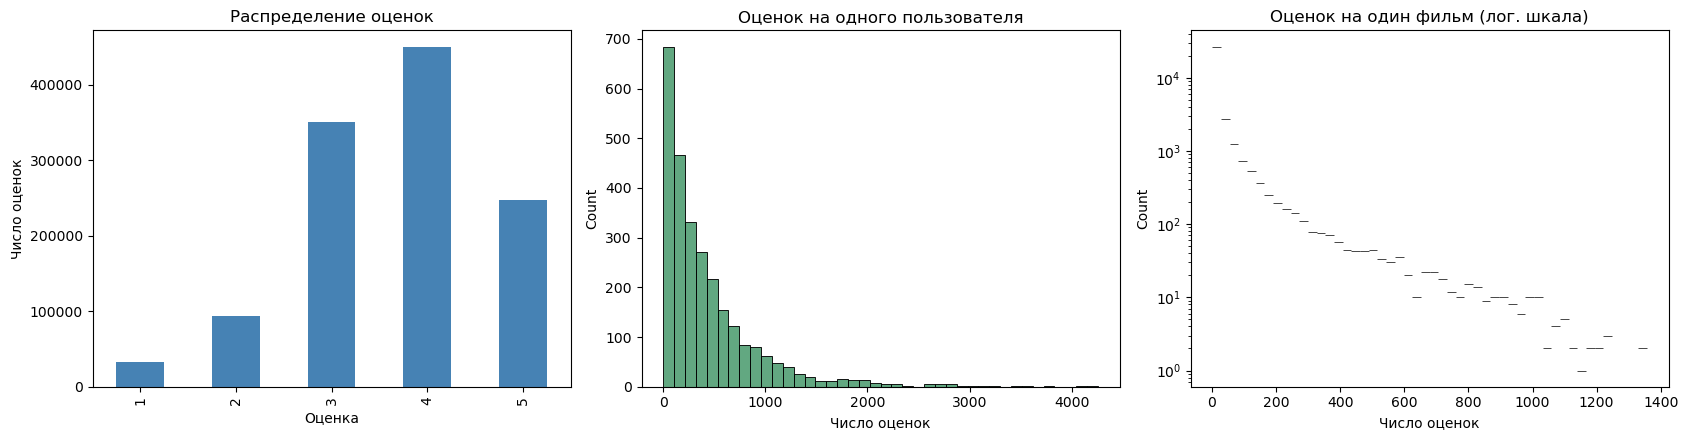

Оценок на пользователя: медиана 276, максимум 4256; на фильм: медиана 7, максимум 1357


In [42]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ratings["rating"].value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Распределение оценок"); ax[0].set_xlabel("Оценка"); ax[0].set_ylabel("Число оценок")
per_user = ratings.groupby("user_id").size()
sns.histplot(per_user, bins=40, ax=ax[1], color="seagreen"); ax[1].set_title("Оценок на одного пользователя"); ax[1].set_xlabel("Число оценок")
per_movie = ratings.groupby("movie_id").size()
sns.histplot(per_movie, bins=50, log_scale=(False, True), ax=ax[2], color="indianred"); ax[2].set_title("Оценок на один фильм (лог. шкала)"); ax[2].set_xlabel("Число оценок")
plt.tight_layout(); plt.show()
print(f"Оценок на пользователя: медиана {per_user.median():.0f}, максимум {per_user.max()}; на фильм: медиана {per_movie.median():.0f}, максимум {per_movie.max()}")

**Выводы.** Оценки смещены вверх: чаще всего ставят 4 и 3, единицы редки (так обычно бывает: люди оценивают то, что им понравилось). У большинства фильмов мало оценок, у нескольких — больше тысячи. Поэтому для надёжных рекомендаций нужна защита от случайных высоких рейтингов у малоизвестных фильмов.

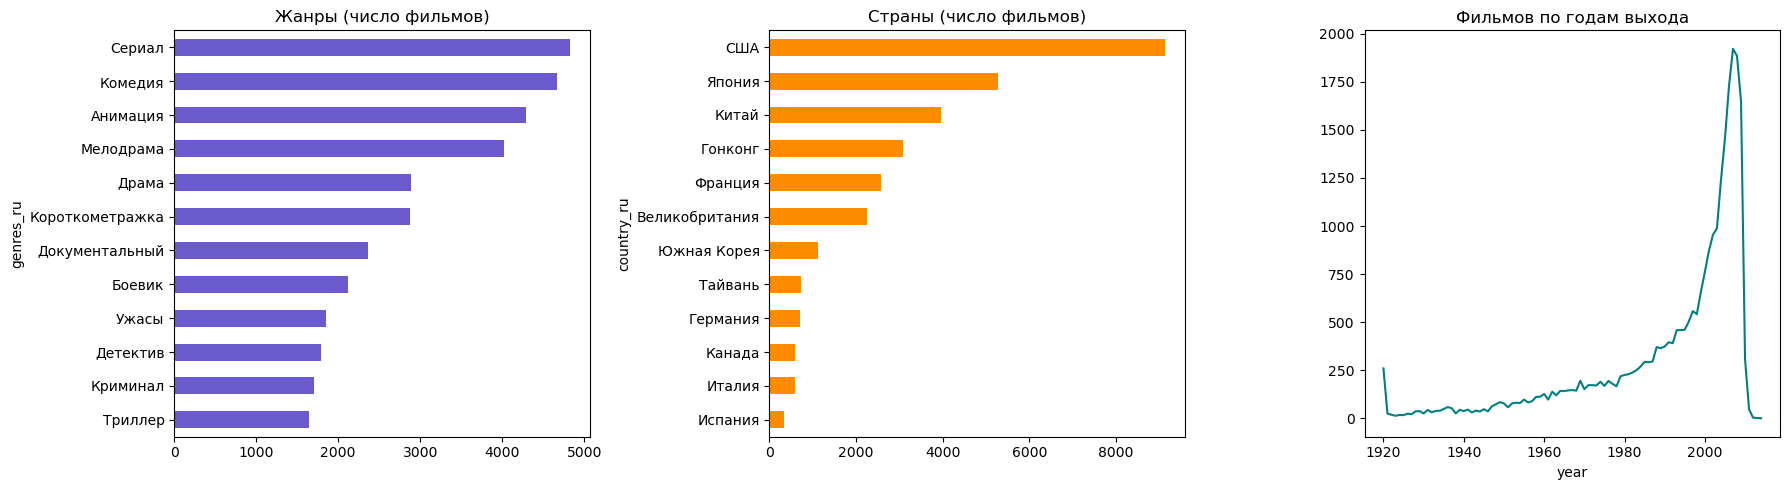

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
g = movies["genres_ru"].str.split(", ").explode()
g[g != "Не указан"].value_counts().head(12).sort_values().plot.barh(ax=ax[0], color="slateblue"); ax[0].set_title("Жанры (число фильмов)")
c = movies["country_ru"].str.split(", ").explode()
c[c != "Не указан"].value_counts().head(12).sort_values().plot.barh(ax=ax[1], color="darkorange"); ax[1].set_title("Страны (число фильмов)")
movies["year"].dropna().astype(int).clip(1920, 2018).value_counts().sort_index().plot(ax=ax[2], color="teal"); ax[2].set_title("Фильмов по годам выхода")
plt.tight_layout(); plt.show()

Самый популярный жанр - сериал
Самая популярная страна - США
Больше всего фильмов начиная с 2000г

## 2. Рекомендации на основе популярности 

нельзя просто брать фильмы с самой высокой средней оценкой — фильм с двумя оценками «5» окажется выше фильма с тысячью оценок «4.7».

In [84]:
avg = ratings.groupby("movie_id")["rating"].mean().rename("avg_rating")
cnt = ratings.groupby("movie_id")["rating"].count().rename("count_rating")
info = movies.set_index("movie_id")[["title_ru", "year", "genres_ru"]]
popularite = pd.concat([avg, cnt], axis=1).join(info)
print("Топ-5 по средней оценке (без учёта числа оценок):")
popularite.sort_values("avg_rating", ascending=False).head(5)

Топ-5 по средней оценке (без учёта числа оценок):


,avg_rating,count_rating,title_ru,year,genres_ru
movie_id,,,,,
34888,5.0,1,SIGhostNAL,NaN,Не указан
18579,5.0,4,北の国から'98時代,1998.0,Не указан
18632,5.0,1,Anticlimax,1973.0,Короткометражка
18636,5.0,1,Raines,2006.0,"Сериал, Криминал"
30815,5.0,1,金田一少年事件簿 135 出雲神話殺人事件 4,NaN,"Анимация, Детектив"


Лидируют фильмы с одной-двумя оценками — это неверный подход.

In [85]:
print("Топ-5 по числу оценок:")
popularite.sort_values("count_rating", ascending=False).head(5)

Топ-5 по числу оценок:


,avg_rating,count_rating,title_ru,year,genres_ru
movie_id,,,,,
31110,4.193073,1357,Первому игроку приготовиться,NaN,"Фантастика, Приключения, Боевик"
16083,4.336310,1344,Interstellar,2009.0,Фантастика
32535,4.352373,1243,Зверополис,NaN,"Анимация, Комедия"
32987,4.063556,1243,Ла-Ла Ленд,NaN,"Мелодрама, Мюзикл, Музыка, Арт-хаус"
33569,4.004065,1230,Дюнкерк,NaN,"Военный, Исторический, Драма"


Таким образом мы получаем самые обсуждаемые фильмы, но не обязательно с хорошим рейтингом.

**Взвешенный рейтинг IMDb (байесовское среднее):**

$$ WR = \frac{v}{v+m}\,R + \frac{m}{v+m}\,C $$

- $v$ — число оценок фильма; $R$ — его средняя оценка;
- $m$ — «порог доверия»: сколько оценок нужно, чтобы рейтингу можно было верить (берём 90-й процентиль числа оценок);
- $C$ — средняя оценка по всем фильмам.

У фильма с малым числом оценок рейтинг «стягивается» к среднему по всем фильмам, а у популярного остаётся почти своим.

In [47]:
v = popularite["count_rating"]
R = popularite["avg_rating"]
m = v.quantile(0.90)       
c = R.mean()               
popularite["w_score"] = (v * R + m * c) / (v + m)
print(f"m (90-й процентиль числа оценок) = {m:.0f}, C (средний рейтинг) = {c:.2f}")
pop_sort = popularite.sort_values("w_score", ascending=False)
top_10_movies = pop_sort.head(10)
top_10_movies

m (90-й процентиль числа оценок) = 78, C (средний рейтинг) = 3.45


,avg_rating,count_rating,title_ru,year,genres_ru,w_score
movie_id,,,,,,
706,4.786116,533,12 Angry Men,1957.0,Драма,4.615567
76,4.748134,536,Дьяволы на пороге,2000.0,Военный,4.583243
2270,4.723022,556,Witness for the Prosecution,1958.0,Детектив,4.566422
31729,4.794118,340,Во все тяжкие (сезон 5),NaN,"Сериал, Криминал, Драма",4.543329
112,4.666667,687,The Shawshank Redemption,1994.0,Драма,4.542629
2045,4.645210,668,Léon,1994.0,"Мелодрама, Боевик",4.520257
1822,4.688787,437,Schindler's List,1993.0,Военный,4.501187
28513,4.575397,1008,Inception,2010.0,Фантастика,4.494578
20191,4.625608,617,WALL•E,2008.0,"Анимация, Фантастика",4.493686


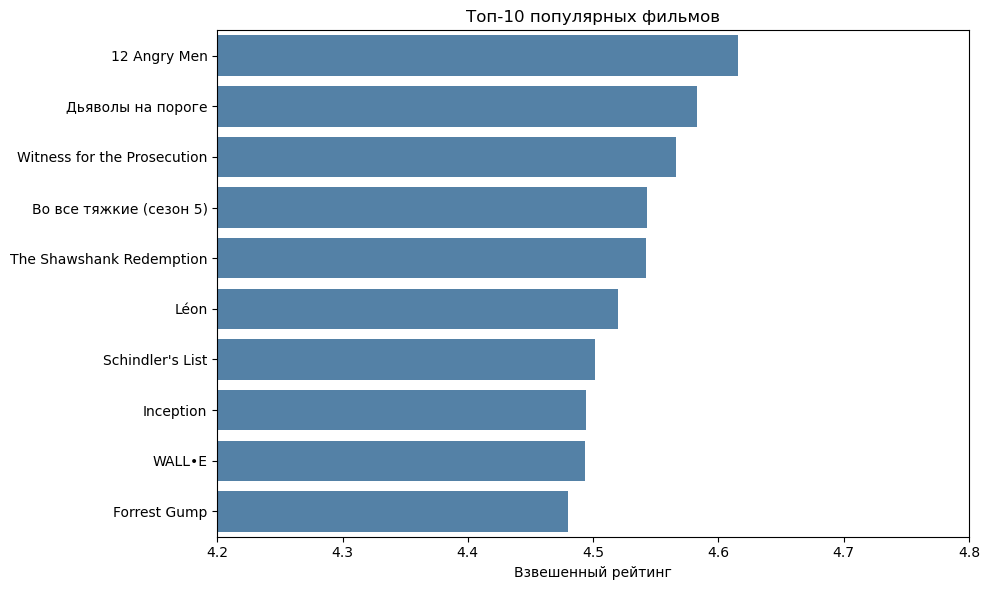

In [48]:
plt.figure(figsize=(10, 6))
sns.barplot(x="w_score", y="title_ru", data=top_10_movies, color="steelblue")
plt.xlim(4.2, 4.8); plt.xlabel("Взвешенный рейтинг"); plt.ylabel("")
plt.title("Топ-10 популярных фильмов")
plt.tight_layout(); plt.show()

Теперь в топе только фильмы, которые оценили сотни человек и в среднем оценили очень высоко. Это и есть **результат для пункта 1 задания** (`GET /movies/popular`). В API добавлены фильтры по жанру и году.

## 3. Коллаборативная фильтрация по фильмам (item-based)

у каждого фильма есть «вектор оценок» — что поставил ему каждый пользователь. Если два вектора похожи, то фильмы нравятся одним и тем же людям. 

In [86]:
def find_id(query):
    mask = movies["title_ru"].str.contains(query, case=False, regex=False) | movies["title_orig"].str.contains(query, case=False, regex=False)
    return int(movies[mask].sort_values("n_ratings", ascending=False).iloc[0]["movie_id"])

title_of = movies.set_index("movie_id")["title_ru"]
tests = {"Зверополис": find_id("Зверополис"), "Начало (Inception)": find_id("Inception"), "Interstellar": find_id("Interstellar")}
tests

{'Зверополис': 32535, 'Начало (Inception)': 28513, 'Interstellar': 16083}

### 3.1 Корреляция Пирсона

Формируем таблицу «пользователь × фильм».
Берём фильмы, у которых не менее 300 оценок, чтобы корреляция была надёжной.

In [87]:
popular_ids = cnt[cnt >= 300].index
users_pivot = ratings[ratings["movie_id"].isin(popular_ids)].pivot_table(index="user_id", columns="movie_id", values="rating")
print("Таблица пользователь × фильм:", users_pivot.shape, f"| заполнено {users_pivot.notna().to_numpy().mean():.1%}")
users_pivot.iloc[:5, :6]

Таблица пользователь × фильм: (2698, 785) | заполнено 19.9%


movie_id,1,3,5,6,8,11
user_id,,,,,,
1,5.0,NaN,NaN,5.0,5.0,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,5.0,NaN,4.0


In [91]:
def same_movies(movie_id, top=10, fill_zero=False, min_overlap=100 ):#минимум оценщиков
    pv = users_pivot.fillna(0) if fill_zero else users_pivot
    corr = pv.corrwith(pv[movie_id])
    overlap = (users_pivot.notna() & users_pivot[[movie_id]].notna().values).sum()   # сколько общих оценщиков
    out = pd.DataFrame({"correlation": corr, "общих оценщиков": overlap}).drop(index=movie_id) # убираем сам тот же фильм
    out = out[out["общих оценщиков"] >= min_overlap].sort_values("correlation", ascending=False).head(top)
    out.insert(0, "фильм", out.index.map(title_of))
    return out

print("С пропусками как NaN (корреляция только по общим оценщикам):")
same_movies(tests["Interstellar"])

С пропусками как NaN (корреляция только по общим оценщикам):


,фильм,correlation,общих оценщиков
movie_id,,,
33470,Человек-швейцарский нож,0.379712,348
28155,Тёмный рыцарь: Возрождение легенды,0.359673,750
29599,Вор времени,0.353643,422
8787,Crash,0.347660,307
33569,Дюнкерк,0.340913,800
32726,"Прощай, до новых встреч",0.320596,753
24618,Hachiko: A Dog's Story,0.318632,389
28513,Inception,0.317365,680
31962,Полёт против света,0.312062,247


In [92]:
same_movies(tests["Interstellar"], fill_zero=True)

,фильм,correlation,общих оценщиков
movie_id,,,
32401,Люси,0.429717,807
29612,Гравитация,0.413513,827
32036,Город героев,0.409213,780
31847,Люди Икс: Дни минувшего будущего,0.401412,754
31814,Мир юрского периода,0.399081,736
30999,На грани будущего,0.397769,758
32057,Отель «Гранд Будапешт»,0.397107,826
32025,Захват горы Тигра,0.381842,710
28744,Безумный Макс: Дорога ярости,0.380230,778




### 3.2 Метод ближайших соседей 

 фильмы — строки, пользователи — признаки, сходство — косинус угла между векторами. Берём фильмы, у которых не менее 20 оценок. Чем больше косинус угла- тем меньше фильмы похожи

In [96]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

ids20 = cnt[cnt >= 20].index
rated = ratings[ratings["movie_id"].isin(ids20)]
u_pos = {u: i for i, u in enumerate(sorted(rated["user_id"].unique()))} # 1 2 3
m_list = sorted(ids20); m_pos = {m: i for i, m in enumerate(m_list)} 
user_item = csr_matrix((rated["rating"].astype("float32"), (rated["user_id"].map(u_pos), rated["movie_id"].map(m_pos))),
                       shape=(len(u_pos), len(m_list)))
print("Матрица пользователь × фильм:", user_item.shape, "| ненулевых значений:", user_item.nnz)

movie_matrix = user_item.T.tocsr()                                  # строки — фильмы
model_knn = NearestNeighbors(metric="cosine", algorithm="brute") # косинусное расстояние: 1 − cos(θ) между векторами оценок, полный перебор всех пар
model_knn.fit(movie_matrix)

def find_similar_movies(movie_id, num_neighbors=10):
    idx = m_pos[movie_id]
    distances, indices = model_knn.kneighbors(movie_matrix[idx], n_neighbors=num_neighbors + 1 ) # ближ сосед, сам фильм 0
    return pd.DataFrame({"фильм": [title_of[m_list[i]] for i in indices[0][1:]], # отбрасываем 1 - сам фильм,
                         "расстояние": distances[0][1:].round(3), # косинусные расстояния (0 = идентичны, 1 = ортогональны, 2 = противоположны)
                         "сходство": (1 - distances[0][1:]).round(3)}) #  сходство (cosine similarity): 1 = идентичны, 0 = не связаны, −1 = противоположны

find_similar_movies(tests["Зверополис"])

Матрица пользователь × фильм: (2711, 9281) | ненулевых значений: 1040169


,фильм,расстояние,сходство
0,Старый пройдоха,0.331,0.669
1,Interstellar,0.333,0.667
2,Головоломка,0.334,0.666
3,Город героев,0.355,0.645
4,Люди Икс: Апокалипсис,0.356,0.644
5,Русалка,0.369,0.631
6,Легенда о расхитителях гробниц,0.369,0.631
7,Твоё имя,0.371,0.629
8,Фантастические твари и где они обитают,0.377,0.623
9,Безумный Макс: Дорога ярости,0.378,0.622


In [54]:
find_similar_movies(tests["Interstellar"])

,фильм,расстояние,сходство
0,Зверополис,0.333,0.667
1,Гравитация,0.336,0.664
2,Life of Pi,0.337,0.663
3,Отель «Гранд Будапешт»,0.342,0.658
4,Люси,0.343,0.657
5,Город героев,0.349,0.651
6,На грани будущего,0.358,0.642
7,Люди Икс: Дни минувшего будущего,0.359,0.641
8,Безумный Макс: Дорога ярости,0.362,0.638
9,Мир юрского периода,0.366,0.634




### 3.3 Матрица косинусного сходства (`cosine_similarity`)
 считаем сразу все пары фильмов и берём 10 с наибольшим сходством. Для компактности берём 3000 самых оцениваемых фильмов.

In [97]:
from sklearn.metrics.pairwise import cosine_similarity

top3000 = cnt.sort_values(ascending=False).head(3000).index
pv = ratings[ratings["movie_id"].isin(top3000)].pivot_table(index="user_id", columns="movie_id", values="rating").fillna(0)
similarity_score = cosine_similarity(pv.T) # 1 - сходство, 0 - не связаны
print("Матрица сходства фильмов:", similarity_score.shape)
pv_T = pv.T #для вытаскивания названия фильма

def recommend(movie_id, top=10):
    if movie_id not in pv_T.index:
        return f"Фильм «{title_of.get(movie_id, movie_id)}» не входит в 3000 самых оцениваемых."
    idx = np.where(pv_T.index == movie_id)[0][0]
    similar = sorted(enumerate(similarity_score[idx]), key=lambda x: x[1], reverse=True)[1:top + 1]
    rows = []
    for i, score in similar:
        mid = pv_T.index[i]
        rows.append({"Фильм": title_of[mid], "Жанры": info.loc[mid, "genres_ru"], "Год": info.loc[mid, "year"], "Сходство": round(score, 3)})
    return pd.DataFrame(rows)

recommend(tests["Interstellar"])

Матрица сходства фильмов: (3000, 3000)


,Фильм,Жанры,Год,Сходство
0,Зверополис,"Анимация, Комедия",NaN,0.667
1,Гравитация,"Фантастика, Катастрофа, Приключения",NaN,0.664
2,Life of Pi,Не указан,2011.0,0.663
3,Отель «Гранд Будапешт»,"Чёрная комедия, Комедия, Арт-хаус, Драма",NaN,0.658
4,Люси,"Фантастика, Боевик, Драма, Криминал",NaN,0.657
5,Город героев,"Анимация, Комедия, Фантастика",NaN,0.651
6,На грани будущего,"Фантастика, Боевик, Военный, Драма",NaN,0.642
7,Люди Икс: Дни минувшего будущего,"Фантастика, Боевик",NaN,0.641
8,Безумный Макс: Дорога ярости,"Боевик, Фантастика, Приключения",NaN,0.638
9,Мир юрского периода,"Фантастика, Приключения, Боевик, Триллер",NaN,0.634


Три способа дают сходные ответы. В API используется вариант 5.2 (косинус) и корреляция Пирсона: `GET /recommendations/item-based/{movie_id}?method=cosine|pearson`. Для быстрой работы в API матрицы строятся один раз при запуске, а не при каждом запросе.

## 4. Коллаборативная фильтрация по пользователям (user-based)

Теперь ищем не похожие фильмы, а **похожих пользователей**. Алгоритм:
1. Находим `k` ближайших по косинусу пользователей (соседей).
2. Берём их оценки и усредняем по каждому фильму с весами: чем ближе сосед, тем больше его вес.
3. Убираем фильмы, которые пользователь уже оценил, и берём 10 лучших.

Сначала посмотрим, что любит выбранный пользователь.

In [98]:
users_pivot2 = rated.pivot_table(index="user_id", columns="movie_id", values="rating").fillna(0).astype("float32")
users_pivot2.columns = [title_of[c] for c in users_pivot2.columns]
print("Матрица пользователь × фильм:", users_pivot2.shape)

def find_favorite_movies(user_id, num_movies=10):
    ratings_u = users_pivot2.loc[user_id].sort_values(ascending=False).head(num_movies)
    return pd.DataFrame({"любимые фильмы": ratings_u.index, "оценка": ratings_u.values})

find_favorite_movies(1)

Матрица пользователь × фильм: (2711, 9281)


,любимые фильмы,оценка
0,Forrest Gump,5.0
1,Разборка в Токио,5.0
2,Lawrence of Arabia,5.0
3,Titanic,5.0
4,Harry Potter and the Chamber of Secrets,5.0
5,В поисках Дори,5.0
6,Memories,5.0
7,Star Wars: Episode V - The Empire Strikes Back,5.0
8,Planet of the Apes,5.0
9,Star Trek Ⅰ: The Motion Picture,5.0


In [101]:
find_favorite_movies(5)

,любимые фильмы,оценка
0,你那边几点？,5.0
1,오아시스,5.0
2,金枝玉叶,5.0
3,天下无双,5.0
4,데이지,5.0
5,馬路天使,5.0
6,La strada,5.0
7,Forrest Gump,5.0
8,Witness for the Prosecution,5.0
9,Полночь в Париже,5.0


In [99]:
user_item_matrix = csr_matrix(users_pivot2.values)
model_user_knn = NearestNeighbors(metric="cosine", algorithm="brute").fit(user_item_matrix)

def find_user_recommendations(user_id, num_neighbors=20, num_movies=10):
    user_index = users_pivot2.index.get_loc(user_id)
    distances, indices = model_user_knn.kneighbors(user_item_matrix[user_index], n_neighbors=num_neighbors + 1)
    similar_user_indices, similar_distances = indices[0][1:], distances[0][1:]      # первый сосед — сам пользователь
    similar_ratings = users_pivot2.iloc[similar_user_indices]
    weights = 1 / (similar_distances + 1e-9)                                         # ближе -> больше вес
    weighted_scores = similar_ratings.T.dot(weights) / weights.sum()
    watched = users_pivot2.loc[user_id]
    weighted_scores = weighted_scores[watched == 0]                                  # исключаем оценённое
    top = weighted_scores.sort_values(ascending=False).head(num_movies)
    return pd.DataFrame({"рекомендованный фильм": top.index, "прогноз (баллы)": top.values.round(3)})

find_user_recommendations(1)

,рекомендованный фильм,прогноз (баллы)
0,Тёмный рыцарь: Возрождение легенды,4.196
1,"Три билборда на границе Эббинга, Миссури",4.155
2,Люди Икс: Дни минувшего будущего,4.093
3,Ла-Ла Ленд,3.793
4,Гравитация,3.746
5,Interstellar,3.698
6,V for Vendetta,3.697
7,The Avengers,3.686
8,The Prestige,3.591
9,Avatar,3.553


In [100]:
find_user_recommendations(5)

,рекомендованный фильм,прогноз (баллы)
0,Fight Club,4.137
1,The Shining,4.050
2,Убийца,4.048
3,The Last Emperor,3.954
4,Паприка,3.842
5,Игра в обман,3.756
6,Dead Poets Society,3.735
7,Первому игроку приготовиться,3.699
8,Отрочество,3.694
9,Inception,3.658


## 5. Рекомендации по содержанию (content-based)

Коллаборативная фильтрация не работает для фильмов, которые почти никто не оценил, и не использует описание фильма. Здесь сравниваем сами фильмы.

**Как строим признаки.** Для каждого фильма составляем «документ» из слов-признаков: жанры (с тройным весом: они самые важные), теги, страна, язык, десятилетие выхода. Затем **TF-IDF** даёт редким признакам (например, «вампиры») больший вес, чем распространённым (например, «США»). Сходство фильмов — косинус между TF-IDF-векторами.

In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer
from api.recommender import RecommenderEngine

def make_tokens(row):
    split = lambda s: [x.strip() for x in str(s).split(",") if x.strip() and x.strip() not in ("Не указан", "nan")]
    toks = [f"жанр:{g}" for g in split(row.genres_ru)] * 3 #жанр:Комедия и повторяется трижды
    toks += [f"тег:{t}" for t in split(row.tags_ru)] + [f"страна:{c}" for c in split(row.country_ru)] + [f"язык:{l}" for l in split(row.language_ru)]
    if pd.notna(row.year): toks.append(f"декада:{int(row.year) // 10 * 10}") # условное округление года, фильм 2000-ых
    return toks

mv = movies.set_index("movie_id", drop=False)
print("Пример «документа» для фильма «Зверополис»:")
print(make_tokens(mv.loc[tests["Зверополис"]]))

Пример «документа» для фильма «Зверополис»:
['жанр:Анимация', 'жанр:Комедия', 'жанр:Анимация', 'жанр:Комедия', 'жанр:Анимация', 'жанр:Комедия', 'тег:США', 'тег:животные', 'тег:Disney', 'тег:2016', 'страна:США', 'язык:Английский', 'язык:Норвежский']


In [60]:
tfidf = TfidfVectorizer(analyzer=lambda d: d, sublinear_tf=True, min_df=2) #Сглаживает эффект повторов: жанр, повторённый ×3, даёт вес не в 3 раза больше, а в 1+log(3) ≈ 2.1 раза
X = tfidf.fit_transform([make_tokens(r) for r in mv.itertuples()])
print("Матрица TF-IDF: фильмов × признаков =", X.shape)
pos = {m: i for i, m in enumerate(mv.index)}

def content_recommend(movie_id, top=10, min_ratings=5):
    sims = cosine_similarity(X[pos[movie_id]], X).ravel() #1 = описания идентичны, 0 = нет общих токенов
    sims[pos[movie_id]] = -1 #обнуляем с самим собой
    sims[mv["n_ratings"].to_numpy() < min_ratings] = -1          # отсекаем фильмы почти без оценок
    best = np.argsort(-sims)[:top]
    return pd.DataFrame({"фильм": mv["title_ru"].to_numpy()[best], "жанры": mv["genres_ru"].to_numpy()[best],
                         "страна": mv["country_ru"].to_numpy()[best], "сходство": sims[best].round(3)})

content_recommend(tests["Зверополис"])

Матрица TF-IDF: фильмов × признаков = (34011, 448)


,фильм,жанры,страна,сходство
0,"Monsters, Inc.","Анимация, Комедия",США,0.682
1,Chicken Little,"Анимация, Комедия",США,0.682
2,Cars,"Анимация, Комедия",США,0.682
3,Mickey's Twice Upon a Christmas,"Анимация, Комедия",США,0.682
4,Inner Workings,"Анимация, Короткометражка, Комедия",США,0.677
5,LEGO Frozen Northern Lights,"Анимация, Короткометражка, Комедия",США,0.677
6,101 Dalmatians,"Комедия, Анимация",США,0.662
7,G-Force,"Анимация, Комедия",США,0.654
8,One Hundred and One Dalmatians,"Анимация, Комедия",США,0.637
9,Over the Hedge,"Анимация, Комедия",США,0.635


In [102]:
content_recommend(tests["Interstellar"])

,фильм,жанры,страна,сходство
0,Quantum Apocalypse,Фантастика,США,0.914
1,I Am Legend,Фантастика,США,0.847
2,珊瑚岛上的死光,Фантастика,Не указан,0.829
3,HINOKIO,Фантастика,Япония,0.817
4,Cutie Honey,Фантастика,Япония,0.817
5,人造人（再造卡辛）,Фантастика,Япония,0.817
6,Robinson Crusoe on Mars,Фантастика,США,0.801
7,Takedown,Фантастика,США,0.798
8,Speed Racer,Фантастика,США,0.797
9,Doctor Who: The Movie,Фантастика,США,0.794


Рекомендации по содержанию совпадают по жанрам, стране и эпохе. Этот метод даёт **пункт 3 задания** (`GET /recommendations/content/{movie_id}`). Минус: он не знает, что нравится зрителям (отсюда в списке бывают проходные фильмы того же жанра), поэтому лучше всего он работает вместе с коллаборативной фильтрацией.

## 6. Персональные рекомендации (гибридные) и класс `RecommenderEngine`

Для пункта 4 задания объединяем два подхода:

$$ \text{score}(f) = \alpha \cdot \text{CF}(f) + (1-\alpha) \cdot \text{Content}(f) $$

- **CF(f)** — сила рекомендации по похожим пользователям ;
- **Content(f)** — сходство фильма с «профилем вкуса» пользователя: профиль — взвешенная сумма TF-IDF-векторов фильмов, которым пользователь поставил 4–5;
- $\alpha = 0.6$ по умолчанию; если у фильма нет прогноза CF (мало оценок у соседей), используется только содержание с небольшим понижением.
- **Холодный старт.** Если у пользователя нет ни одной оценки, показываем популярные фильмы.

Все методы собраны в класс `RecommenderEngine` (файл `api/recommender.py`), который использует API.

In [62]:
import time
t0 = time.time()
engine = RecommenderEngine(movies[["movie_id", "title_ru", "title_orig", "year", "genres_ru", "tags_ru", "country_ru", "language_ru", "director_ru"]], ratings)
print(f"Модель построена за {time.time() - t0:.1f} с | пользователей: {len(engine.user_ids)}, фильмов: {len(engine.movie_ids)}, "
      f"фильмов в item-based: {len(engine.item_cols)}")

def show(res, cols=("title_ru", "year", "genres_ru", "avg_rating", "n_ratings", "score")):
    return pd.DataFrame(res)[list(cols)].rename(columns={"title_ru": "фильм", "year": "год", "genres_ru": "жанры", "avg_rating": "ср. оценка", "n_ratings": "оценок", "score": "значение"})

print("1. Топ-10 популярных:")
show(engine.popular(10))

Модель построена за 1.5 с | пользователей: 2712, фильмов: 34011, фильмов в item-based: 9281
1. Топ-10 популярных:


,фильм,год,жанры,ср. оценка,оценок,значение
0,12 Angry Men,1957.0,Драма,4.79,533,4.6156
1,Дьяволы на пороге,2000.0,Военный,4.75,536,4.5832
2,Witness for the Prosecution,1958.0,Детектив,4.72,556,4.5664
3,Во все тяжкие (сезон 5),NaN,"Сериал, Криминал, Драма",4.79,340,4.5433
4,The Shawshank Redemption,1994.0,Драма,4.67,687,4.5426
5,Léon,1994.0,"Мелодрама, Боевик",4.65,668,4.5203
6,Schindler's List,1993.0,Военный,4.69,437,4.5012
7,Inception,2010.0,Фантастика,4.58,1008,4.4946
8,WALL•E,2008.0,"Анимация, Фантастика",4.63,617,4.4937
9,Forrest Gump,1994.0,Не указан,4.62,564,4.4799


In [63]:
print("2а. Похожие фильмы (по фильмам, cosine) для «Зверополис»:")
show(engine.item_based(tests["Зверополис"], 10, "cosine"))

2а. Похожие фильмы (по фильмам, cosine) для «Зверополис»:


,фильм,год,жанры,ср. оценка,оценок,значение
0,Старый пройдоха,NaN,Драма,3.82,1103,0.6691
1,Interstellar,2009.0,Фантастика,4.34,1344,0.6668
2,Головоломка,NaN,"Анимация, Комедия",4.28,1009,0.6663
3,Город героев,NaN,"Анимация, Комедия, Фантастика",3.98,1005,0.6447
4,Люди Икс: Апокалипсис,NaN,"Фантастика, Боевик",3.56,880,0.6437
5,Русалка,NaN,"Комедия, Мелодрама, Фэнтези",2.89,1017,0.6309
6,Легенда о расхитителях гробниц,2009.0,"Ужасы, Детектив",3.39,991,0.6308
7,Твоё имя,NaN,"Анимация, Мелодрама, Молодёжный",4.00,1065,0.6294
8,Фантастические твари и где они обитают,NaN,"Фэнтези, Приключения, Фантастика",3.62,967,0.6232
9,Безумный Макс: Дорога ярости,NaN,"Боевик, Фантастика, Приключения",4.25,1031,0.6223


In [64]:
print("2б. Рекомендации по пользователям для пользователя №1:")
show(engine.user_based(1, 10))

2б. Рекомендации по пользователям для пользователя №1:


,фильм,год,жанры,ср. оценка,оценок,значение
0,Interstellar,2009.0,Фантастика,4.34,1344,4.6192
1,Тёмный рыцарь: Возрождение легенды,NaN,"Фантастика, Боевик, Криминал",4.12,1020,4.5900
2,"Три билборда на границе Эббинга, Миссури",NaN,"Драма, Криминал, Чёрная комедия",4.23,1206,4.4564
3,По соображениям совести,NaN,"Военный, Исторический",4.05,1053,4.3715
4,Ла-Ла Ленд,NaN,"Мелодрама, Мюзикл, Музыка, Арт-хаус",4.06,1243,4.2776
5,Безумный Макс: Дорога ярости,NaN,"Боевик, Фантастика, Приключения",4.25,1031,4.4059
6,Головоломка,NaN,"Анимация, Комедия",4.28,1009,4.6334
7,Люди Икс: Дни минувшего будущего,NaN,"Фантастика, Боевик",4.01,964,4.3232
8,Твоё имя,NaN,"Анимация, Мелодрама, Молодёжный",4.00,1065,4.1624
9,Невидимый гость,NaN,"Детектив, Криминал, Драма",4.02,1064,4.2622


In [65]:
print("3. Рекомендации по содержанию для «Зверополис»:")
show(engine.content_based(tests["Зверополис"], 10))

3. Рекомендации по содержанию для «Зверополис»:


,фильм,год,жанры,ср. оценка,оценок,значение
0,"Monsters, Inc.",2001.0,"Анимация, Комедия",4.28,384,0.6818
1,Chicken Little,2005.0,"Анимация, Комедия",3.16,32,0.6818
2,Cars,2006.0,"Анимация, Комедия",3.89,168,0.6818
3,Mickey's Twice Upon a Christmas,2004.0,"Анимация, Комедия",3.57,7,0.6818
4,Inner Workings,NaN,"Анимация, Короткометражка, Комедия",3.73,51,0.6765
5,LEGO Frozen Northern Lights,NaN,"Анимация, Короткометражка, Комедия",3.33,6,0.6765
6,101 Dalmatians,1997.0,"Комедия, Анимация",3.48,58,0.6617
7,G-Force,2009.0,"Анимация, Комедия",3.30,112,0.6542
8,One Hundred and One Dalmatians,1962.0,"Анимация, Комедия",4.06,48,0.6372
9,Over the Hedge,2006.0,"Анимация, Комедия",3.68,38,0.6347


In [66]:
print("4. Персональные рекомендации для пользователя №1 (с вкладом каждой части):")
show(engine.personal(1, limit=10), ("title_ru", "genres_ru", "score", "cf_score", "content_score")).rename(columns={"cf_score": "CF", "content_score": "содержание"})

4. Персональные рекомендации для пользователя №1 (с вкладом каждой части):


,фильм,жанры,значение,CF,содержание
0,Interstellar,Фантастика,0.8943,1.000,0.736
1,Тёмный рыцарь: Возрождение легенды,"Фантастика, Боевик, Криминал",0.8292,0.940,0.663
2,Terminator 2: Judgment Day,"Фантастика, Боевик",0.7944,0.657,1.000
3,V for Vendetta,"Фантастика, Боевик, Драма",0.7927,0.757,0.847
4,The Matrix,"Фантастика, Боевик",0.7716,0.637,0.974
5,На грани будущего,"Фантастика, Боевик, Военный, Драма",0.7658,0.799,0.716
6,Люди Икс: Дни минувшего будущего,"Фантастика, Боевик",0.7642,0.823,0.676
7,Avatar,"Фантастика, Военный",0.7287,0.759,0.683
8,Безумный Макс: Дорога ярости,"Боевик, Фантастика, Приключения",0.7257,0.833,0.565
9,Мир юрского периода,"Фантастика, Приключения, Боевик, Триллер",0.7197,0.780,0.630


**Новый пользователь и обновление рекомендаций после оценок.** Смоделируем то, что происходит в приложении: пользователь только зарегистрировался, оценил несколько фильмов — и рекомендации меняются.

In [67]:
print("Новый пользователь без оценок -> холодный старт (популярные):")
show(engine.personal(999999, ratings={}, limit=5), ("title_ru", "genres_ru", "score", "reason"))

Новый пользователь без оценок -> холодный старт (популярные):


,фильм,жанры,значение,reason
0,12 Angry Men,Драма,4.6156,холодный старт: популярное
1,Дьяволы на пороге,Военный,4.5832,холодный старт: популярное
2,Witness for the Prosecution,Детектив,4.5664,холодный старт: популярное
3,Во все тяжкие (сезон 5),"Сериал, Криминал, Драма",4.5433,холодный старт: популярное
4,The Shawshank Redemption,Драма,4.5426,холодный старт: популярное


In [68]:
mine = {find_id("Зверополис"): 5, find_id("Головоломка"): 5, find_id("Тайна Коко"): 4, find_id("Город героев"): 5, find_id("Унесённые призраками"): 5}
print("Оценки нового пользователя:", {title_of[k]: v for k, v in mine.items()})
print("\nПерсональные рекомендации после этих оценок:")
show(engine.personal(999999, ratings=mine, limit=10), ("title_ru", "genres_ru", "score", "cf_score", "content_score"))

Оценки нового пользователя: {'Зверополис': 5, 'Головоломка': 5, 'Тайна Коко': 4, 'Город героев': 5, 'Унесённые призраками': 5}

Персональные рекомендации после этих оценок:


,фильм,жанры,значение,cf_score,content_score
0,Первому игроку приготовиться,"Фантастика, Приключения, Боевик",0.6666,1.000,0.167
1,Путешествие на Запад: Возвращение Великого Муд...,"Анимация, Фэнтези",0.5818,0.639,0.496
2,Interstellar,Фантастика,0.5530,0.782,0.210
3,Мой сосед Тоторо,Анимация,0.5405,0.467,0.651
4,Мстители: Война бесконечности,"Фантастика, Боевик",0.5401,0.780,0.180
5,Твоё имя,"Анимация, Мелодрама, Молодёжный",0.5379,0.582,0.472
6,"Monsters, Inc.","Анимация, Комедия",0.5184,0.215,0.973
7,Гадкий я 3,"Комедия, Анимация",0.4777,0.216,0.871
8,Стражи Галактики. Часть 2,"Фантастика, Комедия",0.4754,0.513,0.419
9,WALL•E,"Анимация, Фантастика",0.4505,0.226,0.787


Новый пользователь, оценивший несколько мультфильмов, сразу получает анимацию и семейное кино. В БД и приложении это происходит без переобучения: вектор пользователя строится из его оценок в момент запроса.

## 7. Оценка качества методов

Проверим, насколько точно методы угадывают то, что пользователю понравится.

**Схема эксперимента:**
1. Берём 300 случайных пользователей, у которых не менее 30 оценок.
2. У каждого скрываем случайные 20% его оценок (тестовая часть), остальное — обучающая.
3. Строим модель **только по обучающим** оценкам и просим каждый метод порекомендовать 10 фильмов, которых пользователь ещё не оценивал.
4. «Угадано» — рекомендованный фильм есть среди скрытых фильмов, которые пользователь оценил на 4–5.

**Метрики:** Precision@10 (какая доля рекомендаций угадана), Recall@10 (какую долю понравившегося мы нашли), HitRate@10 (у скольких пользователей есть хотя бы одно попадание), а также разнообразие (сколько разных фильмов система предложила в сумме).

Для сравнения добавляем метод «только популярные» (одинаковые рекомендации для всех).

In [104]:
rng = np.random.default_rng(42)
per_user = ratings.groupby("user_id").size()
test_users = rng.choice(per_user[per_user >= 30].index.to_numpy(), size=300, replace=False)

sub = ratings[ratings["user_id"].isin(test_users)]
hold = sub.groupby("user_id", group_keys=False).sample(frac=0.2, random_state=42)
train = ratings.drop(hold.index)
print(f"Оценок всего: {len(ratings)} | скрыто для теста: {len(hold)} | обучающих: {len(train)}")

eng = RecommenderEngine(movies[["movie_id", "title_ru", "title_orig", "year", "genres_ru", "tags_ru", "country_ru", "language_ru", "director_ru"]], train)
train_by_user = {u: dict(zip(g["movie_id"], g["rating"].astype(float))) for u, g in train[train["user_id"].isin(test_users)].groupby("user_id")}
relevant = {u: set(g.loc[g["rating"] >= 4, "movie_id"]) for u, g in hold.groupby("user_id")}

Оценок всего: 1175057 | скрыто для теста: 29568 | обучающих: 1145489


In [105]:
def item_cf_for_user(ratings_u, k_liked=8, per_item=30, limit=10):
    liked = sorted(ratings_u.items(), key=lambda x: -x[1])[:k_liked]
    scores = collections.defaultdict(float)
    for mid, r in liked:
        for rec in eng.item_based(mid, per_item, "cosine"):
            scores[rec["movie_id"]] += rec["score"] * (r / 5)
    for mid in ratings_u: scores.pop(mid, None)
    return [m for m, _ in sorted(scores.items(), key=lambda x: -x[1])[:limit]]

def popular_for_user(ratings_u, limit=10):
    return [r["movie_id"] for r in eng.popular(200) if r["movie_id"] not in ratings_u][:limit]

methods = {
    "Популярные (для всех одинаково)": lambda u, r: popular_for_user(r),
    "По фильмам (item-based)":         lambda u, r: item_cf_for_user(r),
    "По пользователям (user-based)":   lambda u, r: [x["movie_id"] for x in eng.user_based(u, 10, ratings=r)],
    "По содержанию (профиль вкуса)":   lambda u, r: [x["movie_id"] for x in eng.personal(u, ratings=r, limit=10, alpha=0.0)],
    "Гибрид (персональные, α=0.6)":    lambda u, r: [x["movie_id"] for x in eng.personal(u, ratings=r, limit=10, alpha=0.6)],
}
rows = []
for name, fn in methods.items():
    P, Rc, H, rec_all = [], [], [], set()
    for u in test_users:
        recs = fn(u, train_by_user[u]); rel = relevant.get(u, set())
        hits = len(set(recs) & rel)
        P.append(hits / 10); Rc.append(hits / len(rel) if rel else 0); H.append(hits > 0); rec_all |= set(recs)
    rows.append({"Метод": name, "Precision@10": np.mean(P), "Recall@10": np.mean(Rc), "HitRate@10": np.mean(H), "Разных фильмов в рекомендациях": len(rec_all)})
results = pd.DataFrame(rows).set_index("Метод")
results.round(3)

,Precision@10,Recall@10,HitRate@10,Разных фильмов в рекомендациях
Метод,,,,
Популярные (для всех одинаково),0.063,0.010,0.310,35
По фильмам (item-based),0.122,0.026,0.553,664
По пользователям (user-based),0.234,0.057,0.793,244
По содержанию (профиль вкуса),0.039,0.012,0.300,934
"Гибрид (персональные, α=0.6)",0.222,0.056,0.773,370


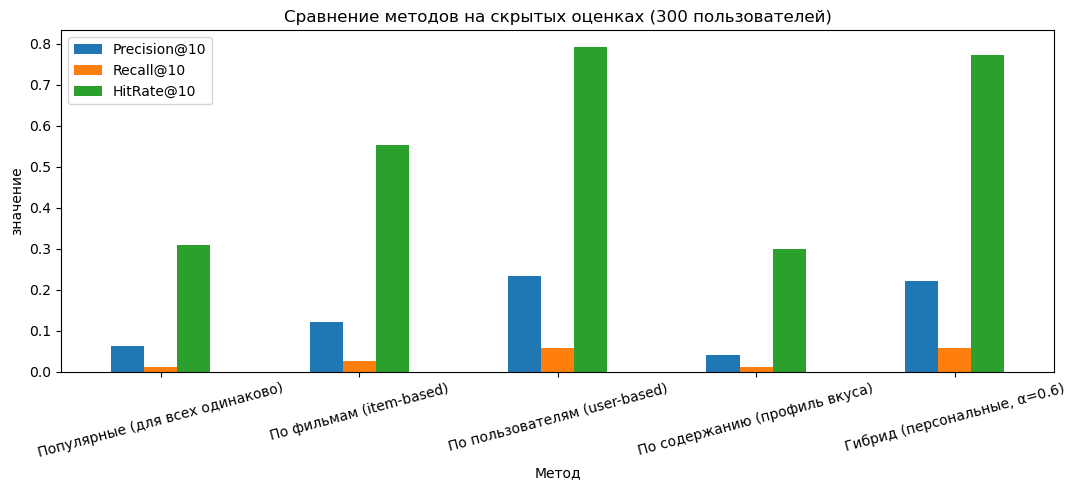

In [106]:
ax = results[["Precision@10", "Recall@10", "HitRate@10"]].plot.bar(figsize=(11, 5), rot=15)
ax.set_title("Сравнение методов на скрытых оценках (300 пользователей)"); ax.set_ylabel("значение")
plt.tight_layout(); plt.show()

## 8. Выводы и ограничения

### Что сделано

| Требование | Результат |
|---|---|
| Датасеты на русском | созданы `movies_ru.csv`, `ratings_ru.csv`, `users_ru.csv` (перевод — словарями, см. ограничения) |
| 4.1 API: топ-10 популярных | `GET /movies/popular` |
| 4.1 API: коллаборативная фильтрация по фильмам и по пользователям | `GET /recommendations/item-based/{id}`, `GET /recommendations/user-based/{id}` |
| 4.1 API: 10 рекомендаций по содержанию | `GET /recommendations/content/{id}` |
| 4.1 API: персональные рекомендации | `GET /recommendations/personal/{id}` |
| 4.2 Приложение с интерфейсом | Tkinter-приложение, работает только через API |
| Оценка фильма и отзыв, хранение в PostgreSQL | `POST /ratings`, таблица `ratings` |
| Справка по командам и параметрам | вкладка «Справка» |

### Результаты сравнения методов 

| Метод | Precision@10 | Recall@10 | HitRate@10 | Разных фильмов |
|---|---|---|---|---|
| Популярные (для всех одинаково) | 0.065 | 0.011 | 0.380 | 31 |
| По фильмам (item-based) | 0.123 | 0.030 | 0.577 | 571 |
| **По пользователям (user-based)** | **0.234** | 0.060 | 0.800 | 256 |
| По содержанию (профиль вкуса) | 0.039 | 0.010 | 0.297 | 941 |
| **Гибрид (персональные, α = 0.6)** | 0.224 | **0.061** | **0.803** | 383 |

1. Персонализация работает: user-based и гибрид находят понравившийся фильм у 80% пользователей против 38% у «одного топа для всех», а точность выше в 3,5 раза.
2. **Гибрид не стал лучше user-based по точности**: 0.224 против 0.234 (разница в пределах случайности), по полноте и числу попаданий они равны. Зато гибрид предлагает более разнообразный набор (383 разных фильма против 256) и работает, когда у похожих пользователей нет данных о фильме. Поэтому он выбран для персональных рекомендаций.
3. Рекомендации **только по содержанию** — самые слабые (0.039): жанров, стран и тегов мало, чтобы угадать вкус. Их роль — подбор «похожих» фильмов и дополнение гибрида.
4. Item-based (0.123) — это «похожие на этот фильм», а не на весь вкус пользователя, поэтому в таком сравнении он уступает user-based; он нужен для кнопки «похожие фильмы».

### Ограничения (честно о том, что не сделано или не проверено)

1. **Перевод на русский неполный.** 
2. Данные относятся к 2018 году и к китайской аудитории (Douban): в рекомендациях преобладают фильмы, популярные в Китае.
   
### Возможные улучшения
улучшения перевода, заполнение года, добавление доп признаков, более новые данные, данные по России